In [1]:
import numpy as np
import matplotlib.pyplot as plt

For b = 0 MeV fm^-3
Ground state energy = 96.528 MeV

For b = 10 MeV fm^-3
Ground state energy = 100.246 MeV

For b = 30 MeV fm^-3
Ground state energy = 106.896 MeV



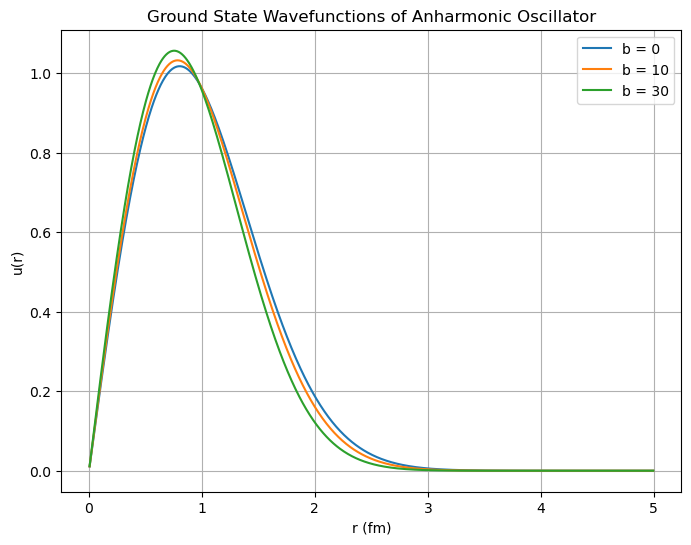

In [ ]:
# Given constants
m = 940
hbar_c = 197.3
k = 100
b_values = [0, 10, 30]

# Radial grid
r_max = 5.0
N = 1000
dr = r_max / (N + 1)
r = np.linspace(dr, r_max - dr, N)

# Kinetic energy coefficient
T = hbar_c**2 / (2 * m * dr**2)

# Plot
plt.figure(figsize=(8, 6))
for b in b_values:
    # Potential energy
    V = 0.5 * k * r**2 + (b / 3) * r**3
    # Construct Hamiltonian matrix
    H = np.zeros((N, N))

    for i in range(N):
        H[i, i] = 2*T + V[i]
        if i > 0:
            H[i, i-1] = -T
        if i < N-1:
            H[i, i+1] = -T

    # Calculate eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(H)
    # Ground state energy
    E0 = eigenvalues[0]
    # Ground state wavefunction
    u = eigenvectors[:, 0]
    # Normalize wavefunction
    u = u / np.sqrt(np.sum(u**2) * dr)
    # Make wavefunction positive
    if u[0] < 0:
        u = -u
    print("For b =", b, "MeV fm^-3")
    print("Ground state energy =", round(E0, 3), "MeV")
    print()
    
    # Plot wavefunction
    plt.plot(r, u, label=f'b = {b}')

# Graph formatting
plt.xlabel('r (fm)')
plt.ylabel('u(r)')
plt.title('Ground State Wavefunctions of Anharmonic Oscillator')
plt.legend()
plt.grid()
plt.show()